In [3]:
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler
from itertools import cycle

def fft_analysis(signal, fs):
    n = len(signal)
    freq = np.fft.fftshift(np.fft.fftfreq(n, 1/fs))
    mag = np.fft.fftshift(np.abs(np.fft.fft(signal)))
    return freq, mag

def smart_plotter(groups, t, fs):
    plt.rcParams.update({
        'axes.grid': True,
        'grid.linestyle': '--',
        'grid.alpha': 0.4,
        'axes.axisbelow': True,  # Grid detrás de los datos
        'axes.prop_cycle': cycler(color=plt.cm.tab10.colors) * cycler(linestyle=['-', '--', '-.', ':'])
    })

    for group in groups:
        fig, ax = plt.subplots(1, 2, figsize=(14, 5))
        fig.suptitle(group['title'], fontsize=14, fontweight='bold')

        # Configuración por defecto
        config = {
            'time': {'legend': 'best', 'xlim': (t[0], t[-1]), 'ylim': None},
            'freq': {'legend': 'best', 'xlim': (-fs/2, fs/2), 'ylim': None}
        }

        # Actualizar configuración personalizada
        if 'config' in group:
            for domain in ['time', 'freq']:
                config[domain].update(group['config'].get(domain, {}))

        # Graficar señales
        for signal_info in group['signals']:
            data = signal_info[0]
            label = signal_info[1]
            style = signal_info[2] if len(signal_info) > 2 else '-'

            # Dominio temporal
            line = ax[0].plot(t, data, style, label=label)[0]
            color = line.get_color()  # Color como string o tupla

            # Dominio frecuencial
            freq, mag = fft_analysis(data, fs)

            # Configurar estilo para stems
            stem_style = style[1:] if len(style) > 1 else '-'

            # Usar color y estilo por separado
            markerline, stemlines, baseline = ax[1].stem(
                freq, mag,
                linefmt=color + stem_style,  # Aplicar estilo aquí
                markerfmt=' ',
                basefmt=color+ stem_style,
                label=label
            )

        # Configuración de ejes
        ax[0].set(xlabel='Tiempo (s)', ylabel='Amplitud',
                 xlim=config['time']['xlim'], ylim=config['time']['ylim'],
                 title='Dominio Temporal')
        ax[1].set(xlabel='Frecuencia (Hz)', ylabel='Magnitud',
                 xlim=config['freq']['xlim'], ylim=config['freq']['ylim'],
                 title='Dominio Frecuencial')

        # Añadir grids y leyendas
        for i, domain in enumerate(['time', 'freq']):
            ax[i].grid(True, which='both', linestyle='--', alpha=0.4)
            ax[i].minorticks_on()
            ax[i].legend(loc=config[domain]['legend'])

        plt.tight_layout()
        plt.show()


def smart_plotter_freq(groups, fs):
    plt.rcParams.update({
        'axes.grid': True,
        'grid.linestyle': '--',
        'grid.alpha': 0.4,
        'axes.axisbelow': True,
        'axes.prop_cycle': cycler(color=plt.cm.tab10.colors)
    })

    for group in groups:
        fig, ax = plt.subplots(figsize=(10, 5))
        fig.suptitle(group['title'], fontsize=14, fontweight='bold')

        # Configuración por defecto
        config = {
            'freq': {'legend': 'best', 'xlim': (-fs/2, fs/2), 'ylim': None}
        }

        if 'config' in group:
            config['freq'].update(group['config'].get('freq', {}))

        for signal_info in group['signals']:
            data = signal_info[0]
            label = signal_info[1]
            style = signal_info[2] if len(signal_info) > 2 else '-'
            show_stemlines = signal_info[3] if len(signal_info) > 3 else False  # Nuevo parámetro

            # Extraer color del estilo (e.g., 'g-' -> 'g')
            color = style[0] if style else plt.rcParams['axes.prop_cycle'].by_key()['color'][0]
            linestyle = style[1:] if len(style) > 1 else ''

            # Dominio frecuencial
            freq, mag = fft_analysis(data, fs)

            # Graficar los marcadores
            markerline, stemlines, baseline = ax.stem(
                freq, mag,
                linefmt=color,  # Sin líneas verticales por defecto
                markerfmt='.',  # Marcadores
                basefmt='',  # Sin línea base por defecto
                label=label
            )

            # Aplicar color personalizado
            plt.setp(markerline, 'color', color)
            plt.setp(markerline, 'markerfacecolor', color)
            plt.setp(markerline, 'markeredgecolor', color)

            # Mostrar u ocultar stemlines y baseline según el parámetro
            if show_stemlines:
                plt.setp(markerline, 'visible', False)
                plt.setp(stemlines, 'color', color)
                plt.setp(stemlines, 'linestyle', linestyle)
                #plt.setp(baseline, 'visible', False)
            else:

                plt.setp(stemlines, 'visible', False)
                plt.setp(baseline, 'visible', False)
        ax.set(
            xlabel='Frecuencia (Hz)',
            ylabel='Magnitud',
            xlim=config['freq']['xlim'],
            ylim=config['freq']['ylim'],
            title='Dominio Frecuencial'
        )

        ax.grid(True, which='both', linestyle='--', alpha=0.4)
        ax.minorticks_on()
        ax.legend(loc=config['freq']['legend'])

        plt.tight_layout()
        plt.show()

def smart_plotter_time(groups, t):
    plt.rcParams.update({
        'axes.grid': True,
        'grid.linestyle': '--',
        'grid.alpha': 0.4,
        'axes.axisbelow': True,
        'axes.prop_cycle': cycler(color=plt.cm.tab10.colors) * cycler(linestyle=['-', '--', '-.', ':'])
    })

    for group in groups:
        fig, ax = plt.subplots(figsize=(10, 5))
        fig.suptitle(group['title'], fontsize=14, fontweight='bold')

        # Configuración por defecto
        config = {
            'legend': 'best',
            'xlim': (t[0], t[-1]),
            'ylim': None
        }

        # Actualizar configuración personalizada si está presente
        if 'config' in group:
            config.update(group['config'].get('time', {}))

        # Graficar señales en el dominio temporal
        for signal_info in group['signals']:
            data = signal_info[0]
            label = signal_info[1]
            style = signal_info[2] if len(signal_info) > 2 else '-'
            ax.plot(t, data, style, label=label)

        # Configurar ejes
        ax.set(
            xlabel='Tiempo (s)',
            ylabel='Amplitud',
            xlim=config['xlim'],
            ylim=config['ylim'],
            title='Dominio Temporal'
        )

        ax.grid(True, which='both', linestyle='--', alpha=0.4)
        ax.minorticks_on()
        ax.legend(loc=config['legend'])

        plt.tight_layout()
        plt.show()



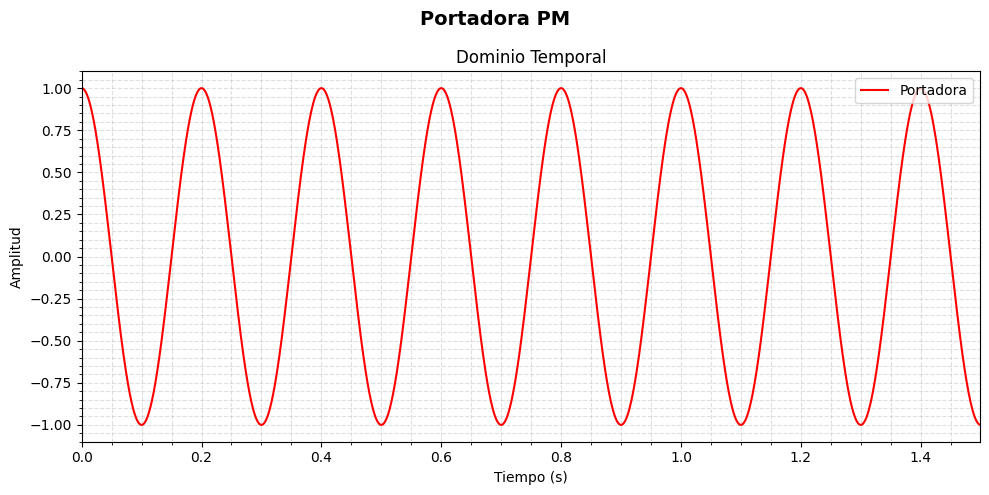

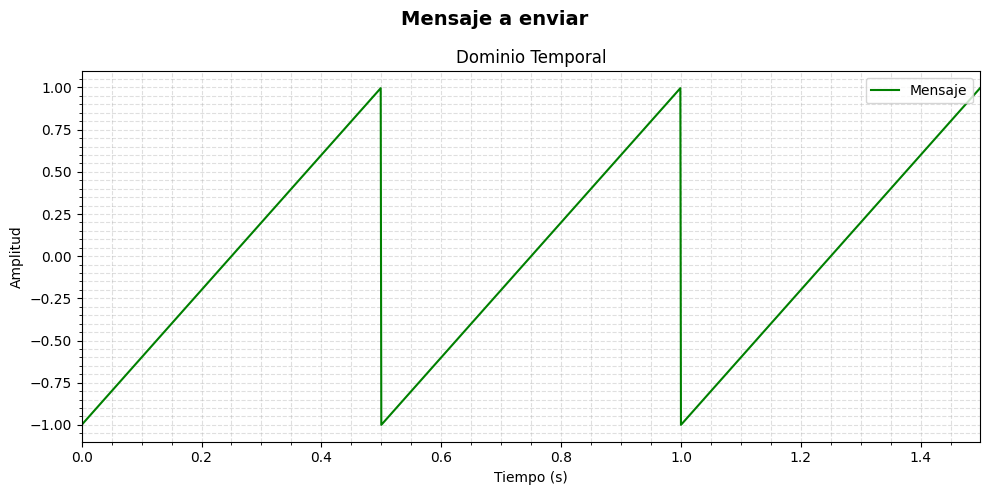

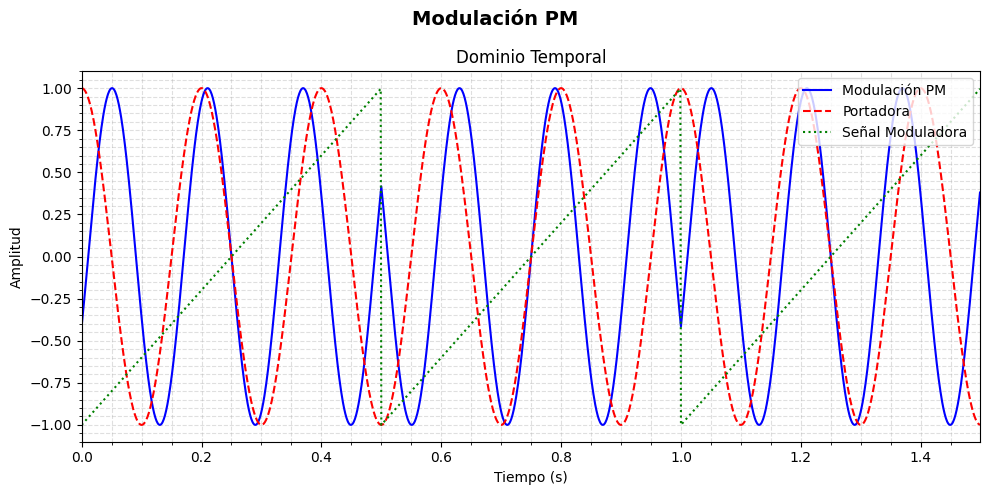

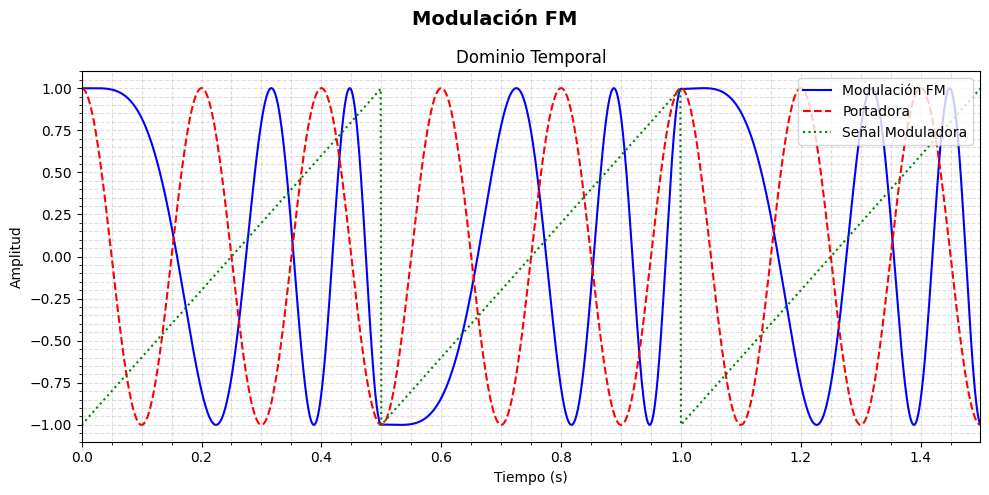

In [10]:
import numpy as np
from scipy.signal import sawtooth

# Parámetros
T0 = 0.5            # Periodo de la señal diente de sierra
periods = 3         # Número de periodos a dibujar
Am = 1              # Amplitud del diente de sierra
Ac = 1              # Amplitud de la portadora
fc = 5              # Frecuencia de la portadora (Hz)
saw_freq = 1 / T0   # Frecuencia de la señal moduladora (Hz)
Ts = 0.001          # Tiempo de muestreo para simulación (s)
kp = 2              # Sensibilidad de fase PM
Deltaf = 5
kf = Deltaf / Am    # Sensibilidad de frecuencia
t = np.arange(0, periods * T0, Ts)  # Vector de tiempo
fs = 1 / Ts

# Señal moduladora
m = sawtooth(2 * np.pi * saw_freq * t)

# Portadora
c = Ac * np.cos(2 * np.pi * fc * t)

# Modulación PM
s_PM = Ac * np.cos(2 * np.pi * fc * t + kp * m)

# Modulación FM
int_m = Ts * np.cumsum(m)
s_FM = Ac * np.cos(2 * np.pi * fc * t + 2 * np.pi * kf * int_m)

# Graficar con smart_plotter_time


portadora = {
        'title': 'Portadora PM',
        'signals': [
            (c, "Portadora", 'r-')
        ],
        'config': {'time': {'legend': 'upper right'}}
    }

mensaje = {
        'title': 'Mensaje a enviar',
        'signals': [
            (m, "Mensaje", 'g-')
        ],
        'config': {'time': {'legend': 'upper right'}}

    }

signal_pm = {
        'title': 'Modulación PM',
        'signals': [
            (s_PM, "Modulación PM", 'b-'),
            (c, "Portadora", 'r--'),
            (m, "Señal Moduladora", 'g:')
        ],
        'config': {'time': {'legend': 'upper right'}}

    }

signal_fm = {
        'title': 'Modulación FM',
        'signals': [
            (s_FM, "Modulación FM", 'b-'),
            (c, "Portadora", 'r--'),
            (m, "Señal Moduladora", 'g:')
        ],
        'config': {'time': {'legend': 'upper right'}}

    }


smart_plotter_time([
    portadora,
    mensaje,
    signal_pm,
    signal_fm

], t)


<ipython-input-39-aed747e8391a>:29: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  integral = np.trapz(np.abs(mixer[:samples_per_period]), dx=Ts)


Beats por segundo: 12.7968	tau*f0 = 0.2	Aproximacion:16.0


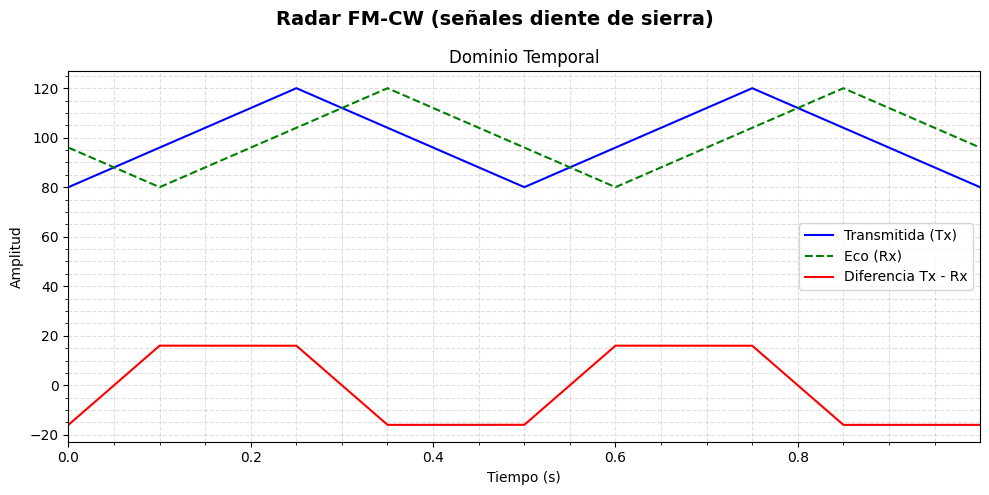

In [39]:
import numpy as np
from scipy.signal import sawtooth

# Parámetros
f0 = 2           # Frecuencia de repetición del diente de sierra (Hz)
fc = 100         # Frecuencia de onda (Hz)
Delta_f = 20     # Desviación (amplitud del diente de sierra)
tau = 0.1        # Retardo (s)
Ts = 1e-4        # Paso temporal
t_max = 1        # Duración total
t = np.arange(0, t_max, Ts)
fs = 1 / Ts      # Frecuencia de muestreo

# Señal Tx
tx = sawtooth(2 * np.pi * f0 * t, width=0.5) * Delta_f + 100

# Señal Rx (retardo)
samples_delay = int(tau / Ts)
rx = np.roll(tx, samples_delay)

# Salida del mixer
mixer = tx - rx

# ✅ Integral del mixer sobre un período
T = 1 / f0                          # Período de repetición
samples_per_period = int(T / Ts)   # Muestras por período

# Tomamos un solo período (por ejemplo, el primero completo)
integral = np.trapz(np.abs(mixer[:samples_per_period]), dx=Ts)
average = integral / T

print(f"Beats por segundo: {average:.4f}\ttau*f0 = {tau*f0}\tAproximacion:{4*Delta_f*tau*f0}")

# Graficar
smart_plotter_time([
    {
        'title': 'Radar FM-CW (señales diente de sierra)',
        'signals': [
            (tx, 'Transmitida (Tx)', 'b-'),
            (rx, 'Eco (Rx)', 'g--'),
            (mixer, 'Diferencia Tx - Rx', 'r-')
        ]
    }
], t)
